# Análisis exploratorio — Oferta gastronómica (punto 1)

**Cliente:** EcoFood
**Rol:** Punto 1 — Oferta gastronómica y mercado actual
**Entrada:** `data/processed/establecimientos_clean.csv` (2.811 locales, limpio)

## Qué busca este notebook

Contestar tres preguntas con evidencia:

1. **¿Cómo está distribuida la oferta** en la Ciudad? (volumen, concentración, densidad)
2. **¿Dónde está la oferta saludable** y en qué barrios hay una brecha real?
3. **¿La baja oferta es una oportunidad o es un equilibrio?** Es decir: ¿hay poca oferta porque nadie la demanda?

## La trampa que hay que evitar

La oferta que medimos es un **equilibrio**, no un vacío. Si un barrio tiene pocos locales, puede ser por dos razones opuestas:

- **Brecha**: hay demanda y nadie la atiende → oportunidad.
- **Equilibrio**: no hay demanda porque la gente resuelve en otra zona → no hay oportunidad.

El dataset solo no distingue entre las dos. Por eso el análisis se hace con **varias miradas en paralelo** y no con un solo ranking. Cada mirada descarta una explicación alternativa distinta.

## Las miradas

| # | Lente | Qué controla |
|---|---|---|
| 1 | Volumen y concentración | Cuánta oferta hay y qué tan repartida está |
| 2 | Densidad y población flotante | Si el barrio se mide por residentes o por gente que pasa |
| 3 | Composición de rubros | Si la diferencia es de segmento o de mezcla de negocios |
| 4 | Nivel de precio revelado | Poder adquisitivo de la zona (proxy interno, sin datos externos) |
| 5 | Espacios verdes | Si el flujo de gente viene de la recreación |
| 6 | Oferta saludable | El segmento de EcoFood |
| 7 | Cruce final | Todo junto, con umbral de volumen |

## Fuentes

| Archivo | Contenido | Origen |
|---|---|---|
| `establecimientos_clean.csv` | 2.811 locales | GCBA — Oferta y Establecimientos Gastronómicos |
| `poblacion_por_barrio.csv` | 48 barrios | GCBA — dataset `barrios`, Censo 2010 |
| `barrios_caba.geojson` | 48 polígonos + área | GCBA — dataset `barrios` |
| `espacios_verdes.csv` | 2.176 espacios verdes | GCBA — dataset `espacios-verdes` |

**Nada de esto sale de scraping ni de fuentes pagas.** Todo es del portal de datos abiertos del GCBA.

## Qué NO cubre

- **Precios reales** de plato ni alquiler: el dataset no los trae. Se aproxima con un proxy (lente 4).
- **Ingreso por hogar**: no hay dato por barrio. Es una limitación declarada.
- **Demanda**: eso es el punto 2 (Google Trends).
- **Serie temporal**: el dataset es una foto, no una evolución.


## 1. Carga de las cuatro fuentes

Cada archivo tiene su propia estructura. Se cargan por separado y se unen recién en el paso 3, para que cualquier error de join se vea aislado.


In [1]:
import json
import unicodedata

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.collections import PatchCollection
from matplotlib.patches import Polygon as MplPolygon
from matplotlib.cm import ScalarMappable
from matplotlib.colors import Normalize

pd.set_option('display.width', 220)
pd.set_option('display.max_columns', 40)

PROC = '../data/processed'
RAW = '../data/raw'

locales = pd.read_csv(f'{PROC}/establecimientos_clean.csv')
poblacion = pd.read_csv(f'{RAW}/poblacion_por_barrio.csv')
verdes = pd.read_csv(f'{RAW}/espacios_verdes.csv')
geo = json.load(open(f'{RAW}/barrios_caba.geojson', encoding='utf-8'))

print('locales:  ', locales.shape)
print('poblacion:', poblacion.shape)
print('verdes:   ', verdes.shape)
print('geometria:', len(geo['features']), 'poligonos')


locales:   (2811, 18)
poblacion: (48, 2)
verdes:    (2176, 5)
geometria: 48 poligonos


## 2. Unir las fuentes: el problema de los nombres

Ninguna de las cuatro fuentes escribe los barrios igual:

| Fuente | Ejemplo |
|---|---|
| Locales (limpio) | `Núñez`, `La Boca`, `La Paternal` |
| Población | `NUÑEZ`, `BOCA`, `PATERNAL` |
| Espacios verdes | `Nuñez`, `La Boca`, `Paternal` |
| Geometría | `NUÑEZ`, `BOCA`, `PATERNAL` |

Si se joinea por texto crudo, `Núñez` y `NUÑEZ` no matchean y el barrio queda sin población.

**Solución:** la misma función `clave()` del notebook de limpieza. Saca tildes, puntos, espacios y pasa a minúsculas. Así `Núñez`, `NUÑEZ` y `Nuñez` colapsan al mismo valor.

Quedan dos casos que no se resuelven solos porque cambia el nombre, no la tilde: `BOCA` → `La Boca` y `PATERNAL` → `La Paternal`. Van en un diccionario de alias, explícito.


In [2]:
def clave(texto):
    """Minúsculas, sin tildes, sin puntos ni espacios. Sirve para comparar nombres."""
    sin_tildes = unicodedata.normalize('NFKD', texto).encode('ascii', 'ignore').decode('utf-8')
    return sin_tildes.lower().replace('.', '').replace(' ', '')


ALIAS = {
    'boca': 'La Boca',
    'paternal': 'La Paternal',
}

# Nuestro nombre canónico es el del dataset de locales (ya normalizado a los 48 oficiales).
canonico = {clave(b): b for b in locales['barrio'].unique()}
canonico.update(ALIAS)

poblacion['barrio'] = poblacion['BARRIO'].map(lambda b: canonico.get(clave(b), b))
verdes['barrio'] = verdes['barrio'].map(lambda b: canonico.get(clave(b), b))

print('barrios de poblacion sin mapear:', sorted(set(poblacion['barrio']) - set(locales['barrio'])))
print('barrios de verdes sin mapear:   ', sorted(set(verdes['barrio']) - set(locales['barrio'])))


barrios de poblacion sin mapear: ['PARQUE CHAS']
barrios de verdes sin mapear:    ['Parque Chas']


Los dos barrios que aparecen "sin mapear" son `Parque Chas` en ambas fuentes: existe en población, en verdes y en la geometría, pero **no tiene ningún local registrado**. Es correcto que quede afuera de las tablas de oferta; se lo muestra en el mapa para que el aviso no se pierda.

Ahora se extrae el área de cada barrio desde el GeoJSON. El campo `AREA` viene en m² y es el que usa el Gobierno para la superficie oficial del barrio.


In [3]:
area_km2 = {}
for feature in geo['features']:
    k = clave(feature['properties']['BARRIO'])
    k = clave(ALIAS.get(k, k))
    area_km2[k] = float(feature['properties']['AREA']) / 1e6

print('poligonos con area:', len(area_km2))
print('area total CABA (km2):', round(sum(area_km2.values()), 1))


poligonos con area: 48
area total CABA (km2): 203.6


## 3. Tabla maestra a nivel barrio

Una fila por barrio, con todos los indicadores. Es la base de todas las lentes.

Los indicadores se calculan así:

| Indicador | Fórmula | Qué mide |
|---|---|---|
| `locales` | conteo | Tamaño absoluto del mercado |
| `loc_10k` | locales / habitantes × 10.000 | Oferta por residente |
| `loc_km2` | locales / km² | Oferta por superficie (captura gente que pasa, no solo que vive) |
| `m2verde_hab` | m² de verde / habitantes | Recreación disponible |
| `share_salud` | saludables / locales × 100 | Peso del segmento saludable |
| `share_alto` | cocinas de ticket alto / locales × 100 | Proxy de poder adquisitivo |
| `share_prem` | ambientación premium / locales × 100 | Segundo proxy, independiente del primero |

**Sobre el umbral de volumen:** un barrio con 2 locales y 0 saludables no es "un barrio sin oferta saludable", es un barrio con 2 locales. Todo ranking de porcentajes se hace con `locales >= 20`, que es el corte que usamos en todo el análisis.


In [4]:
UMBRAL_VOLUMEN = 20

# --- cocinas y ambientaciones que funcionan como proxy de ticket alto ---
# Se eligen por nombre exacto, no por substring (evita que FIT matchee CONFITERIA).
COCINA_TICKET_ALTO = {
    'DE AUTOR', 'GOURMET', 'FUSION', 'CONTEMPORANEA', 'FRANCESA', 'TAPAS',
    'MARISCOS', 'PATAGONICA', 'TAILANDESA', 'MEDITERRANEA', 'SUSHI', 'JAPONESA',
}
AMBIENTACION_PREMIUM = {
    'ELEGANTE', 'DISEÑO', 'MINIMALISTA', 'VANGUARDISTA', 'ART- DECO', 'ART DECO',
    'ROMANTICO', 'LITERARIO',
}

locales['cocina_norm'] = locales['cocina'].str.upper().str.strip()
locales['ambiente_norm'] = locales['ambientacion'].str.upper().str.strip()
locales['ticket_alto'] = locales['cocina_norm'].isin(COCINA_TICKET_ALTO)
locales['ambiente_premium'] = locales['ambiente_norm'].isin(AMBIENTACION_PREMIUM)

tabla = locales.groupby('barrio').agg(
    locales=('id', 'size'),
    salud_estricto=('es_saludable_estricto', 'sum'),
    salud_amplio=('es_saludable_amplio', 'sum'),
    ticket_alto=('ticket_alto', 'sum'),
    ambiente_premium=('ambiente_premium', 'sum'),
)
tabla['zona'] = locales.groupby('barrio')['zona'].first()
tabla = tabla.join(poblacion.set_index('barrio')['POBLACION'].rename('poblacion'))
tabla['km2'] = [area_km2.get(clave(b)) for b in tabla.index]
tabla['verde_km2'] = (verdes.groupby('barrio')['area_m2'].sum() / 1e6).reindex(tabla.index).fillna(0)

tabla['loc_10k'] = (tabla['locales'] / tabla['poblacion'] * 10_000).round(1)
tabla['loc_km2'] = (tabla['locales'] / tabla['km2']).round(1)
tabla['m2verde_hab'] = (tabla['verde_km2'] * 1e6 / tabla['poblacion']).round(1)
tabla['share_salud'] = (tabla['salud_amplio'] / tabla['locales'] * 100).round(1)
tabla['share_alto'] = (tabla['ticket_alto'] / tabla['locales'] * 100).round(1)
tabla['share_prem'] = (tabla['ambiente_premium'] / tabla['locales'] * 100).round(1)

print('barrios en la tabla:', len(tabla))
print('columnas con nulos:', tabla.isna().sum().to_dict())
print('locales totales:', int(tabla['locales'].sum()))


barrios en la tabla: 47
columnas con nulos: {'locales': 0, 'salud_estricto': 0, 'salud_amplio': 0, 'ticket_alto': 0, 'ambiente_premium': 0, 'zona': 0, 'poblacion': 0, 'km2': 0, 'verde_km2': 0, 'loc_10k': 0, 'loc_km2': 0, 'm2verde_hab': 0, 'share_salud': 0, 'share_alto': 0, 'share_prem': 0}
locales totales: 2811


Si alguna columna tiene nulos, el join falló en algún lado y hay que parar acá. No se sigue con datos incompletos.


In [5]:
tabla.sort_values('locales', ascending=False)[[
    'zona', 'locales', 'poblacion', 'km2', 'loc_10k', 'loc_km2',
    'm2verde_hab', 'share_salud', 'share_alto', 'share_prem',
]].head(12).round(2)


,zona,locales,poblacion,km2,loc_10k,loc_km2,m2verde_hab,share_salud,share_alto,share_prem
barrio,,,,,,,,,,
Palermo,Norte,466,226534,15.85,20.6,29.4,9.8,7.1,13.1,5.8
San Nicolás,Centro,454,29273,2.29,155.1,198.3,2.5,1.8,2.2,0.7
Recoleta,Norte,324,157932,6.32,20.5,51.3,2.1,2.2,4.9,1.9
Balvanera,Centro,212,138926,4.34,15.3,48.8,0.2,0.5,1.4,1.4
Monserrat,Centro,148,39914,2.20,37.1,67.3,2.0,0.7,1.4,0.0
Caballito,Oeste,124,176076,6.85,7.0,18.1,1.0,3.2,4.0,8.9
Retiro,Centro,109,65413,4.51,16.7,24.2,2.4,5.5,9.2,2.8
Flores,Oeste,85,164310,8.59,5.2,9.9,1.4,0.0,0.0,0.0
San Telmo,Centro,80,20453,1.23,39.1,64.9,3.4,1.2,3.8,0.0


## 4. Lente 1 — Volumen y concentración

**Pregunta:** ¿la oferta está repartida o concentrada?

Dos medidas:

- **Top 5 share**: qué porcentaje de los locales está en los 5 barrios más grandes. Si es muy alto, el mercado está centralizado.
- **HHI** (Índice Herfindahl-Hirschman) sobre la mezcla de rubros por zona. Suma de las participaciones al cuadrado, escalada a 10.000. Valores bajos = mercado diversificado; altos = dominado por un rubro.

El HHI acá no mide competencia entre locales (no tenemos ventas), mide **diversidad de rubros dentro de la zona**. Es una aproximación, y se declara como tal.


In [6]:
por_zona = locales.groupby('zona', observed=True).agg(
    locales=('id', 'size'),
    salud_amplio=('es_saludable_amplio', 'sum'),
    salud_estricto=('es_saludable_estricto', 'sum'),
)
por_zona['poblacion'] = tabla.groupby('zona')['poblacion'].sum()
por_zona['share_del_total'] = (por_zona['locales'] / por_zona['locales'].sum() * 100).round(1)
por_zona['loc_10k'] = (por_zona['locales'] / por_zona['poblacion'] * 10_000).round(1)
por_zona['share_salud'] = (por_zona['salud_amplio'] / por_zona['locales'] * 100).round(2)
por_zona['salud_por_100k'] = (por_zona['salud_amplio'] / por_zona['poblacion'] * 100_000).round(1)
por_zona.sort_values('locales', ascending=False)


,locales,salud_amplio,salud_estricto,poblacion,share_del_total,loc_10k,share_salud,salud_por_100k
zona,,,,,,,,
Centro,1090,23,2,393423,38.8,27.7,2.11,5.8
Norte,999,48,7,815349,35.5,12.3,4.80,5.9
Sur,363,1,1,912306,12.9,4.0,0.28,0.1
Oeste,359,8,1,751584,12.8,4.8,2.23,1.1


In [7]:
# Concentración: cuánto pesan los 5 barrios más grandes
top5 = tabla.nlargest(5, 'locales')
share_top5 = top5['locales'].sum() / tabla['locales'].sum() * 100

print(f'Top 5 barrios: {top5["locales"].sum()} de {tabla["locales"].sum()} locales = {share_top5:.1f}%')
print(top5[['locales']].assign(pct=(top5['locales'] / tabla['locales'].sum() * 100).round(1)).to_string())

print()
hhi = {}
for zona, sub in locales.groupby('zona', observed=True):
    cuotas = sub['categoria'].value_counts(normalize=True)
    hhi[zona] = round((cuotas ** 2).sum() * 10_000)

for zona, valor in sorted(hhi.items(), key=lambda x: -x[1]):
    mezcla = locales[locales['zona'] == zona]['categoria'].value_counts(normalize=True).head(3)
    detalle = ', '.join(f'{k} {v*100:.0f}%' for k, v in mezcla.items())
    print(f'{zona:8s} HHI={valor:5d}  |  {detalle}')


Top 5 barrios: 1604 de 2811 locales = 57.1%
             locales   pct
barrio                    
Palermo          466  16.6
San Nicolás      454  16.2
Recoleta         324  11.5
Balvanera        212   7.5
Monserrat        148   5.3

Norte    HHI= 5670  |  RESTAURANTE 74%, CAFE 11%, BAR 8%


Centro   HHI= 5068  |  RESTAURANTE 69%, CAFE 13%, BAR 12%
Sur      HHI= 5049  |  RESTAURANTE 69%, CAFE 10%, SIN DATO 7%
Oeste    HHI= 4780  |  RESTAURANTE 67%, CAFE 13%, SIN DATO 10%


## 5. Lente 2 — Densidad y población flotante

**Pregunta:** ¿la oferta se mide por residentes o por gente que pasa?

Acá está el punto que rompe el análisis ingenuo. Un barrio puede tener poca oferta por habitante y mucha por superficie (o al revés). La diferencia entre los dos rankings es un proxy de cuánta gente **no residente** circula.

- **Mucho más alto por superficie que por habitante** → barrio de oficinas, turismo o tránsito. Ejemplo clásico: Puerto Madero.
- **Mucho más alto por habitante que por superficie** → barrio residencial denso, poca actividad comercial. Ejemplo: Almagro.

`rank_diff = rank(loc_km2) - rank(loc_10k)`. Positivo grande = mide mucho mejor por superficie (gente de paso). Negativo grande = lo contrario.


In [8]:
tabla['rank_km2'] = tabla['loc_km2'].rank(ascending=False).astype(int)
tabla['rank_10k'] = tabla['loc_10k'].rank(ascending=False).astype(int)
tabla['rank_diff'] = tabla['rank_km2'] - tabla['rank_10k']

print('=== Los 10 barrios con más oferta por superficie ===')
print(tabla.nlargest(10, 'loc_km2')[[
    'locales', 'km2', 'loc_km2', 'loc_10k', 'rank_km2', 'rank_10k', 'rank_diff',
]].to_string())

print()
print('=== Donde más cambia el ranking (efecto población flotante) ===')
print(tabla.reindex(tabla['rank_diff'].abs().sort_values(ascending=False).index)[[
    'locales', 'loc_km2', 'loc_10k', 'rank_km2', 'rank_10k', 'rank_diff',
]].head(8).to_string())


=== Los 10 barrios con más oferta por superficie ===
             locales        km2  loc_km2  loc_10k  rank_km2  rank_10k  rank_diff
barrio                                                                          
San Nicolás      454   2.289008    198.3    155.1         1         1          0
Monserrat        148   2.198622     67.3     37.1         2         4         -2
San Telmo         80   1.232270     64.9     39.1         3         3          0
Recoleta         324   6.317265     51.3     20.5         4         6         -2
Balvanera        212   4.342280     48.8     15.3         5         8         -3
Palermo          466  15.845871     29.4     20.6         6         5          1
Retiro           109   4.512711     24.2     16.7         7         7          0
Caballito        124   6.851029     18.1      7.0         8        14         -6
Colegiales        40   2.289774     17.5      7.6         9        12         -3
Almagro           63   4.050752     15.6      4.8       

**Cómo se lee:** Puerto Madero sube 14 puestos cuando se mide por superficie. No es que tenga "más restaurantes de los que parecen": es que tiene muy pocos residentes en relación a la actividad que soporta. Cualquier conclusión basada en habitantes por barrio va a castigar a los barrios de oficinas y premiar a los dormitorios, y eso hay que decirlo.

## 6. Lente 3 — Composición de rubros

**Pregunta:** ¿el Sur tiene poca oferta saludable porque tiene poco de todo, o porque su mezcla de rubros es distinta?

Si la composición de rubros es parecida en todas las zonas, la diferencia está en el **segmento**, no en la estructura del mercado.


In [9]:
mezcla_categoria = pd.crosstab(locales['categoria'], locales['zona'], normalize='columns') * 100
mezcla_categoria.round(1).loc[['RESTAURANTE', 'CAFE', 'BAR', 'CONFITERIA', 'PUB', 'VINERIA', 'SIN DATO']]


zona,Centro,Norte,Oeste,Sur
categoria,,,,
RESTAURANTE,68.9,74.0,66.9,69.4
CAFE,13.0,10.7,12.5,10.5
BAR,11.8,8.2,2.8,6.6
CONFITERIA,2.6,0.7,1.4,4.1
PUB,0.9,1.4,6.1,1.9
VINERIA,1.1,1.0,0.0,0.0
SIN DATO,1.6,3.5,10.3,7.4


In [10]:
for zona in ['Centro', 'Norte', 'Oeste', 'Sur']:
    sub = locales[locales['zona'] == zona]
    top = sub['cocina'].value_counts(normalize=True).head(4) * 100
    detalle = ' | '.join(f'{k} {v:.0f}%' for k, v in top.items())
    print(f'{zona:7s} n={len(sub):5d}  {detalle}')


Centro  n= 1090  MINUTAS 32% | INTERNACIONAL 21% | SIN DATO 13% | TRADICIONAL 11%
Norte   n=  999  MINUTAS 20% | SIN DATO 16% | INTERNACIONAL 14% | TRADICIONAL 11%
Oeste   n=  359  MINUTAS 24% | PARRILLA 12% | PIZZERIA 12% | SIN DATO 11%
Sur     n=  363  MINUTAS 28% | INTERNACIONAL 15% | PIZZERIA 13% | PARRILLA 9%


## 7. Lente 4 — Nivel de precio revelado (proxy de poder adquisitivo)

**El problema:** no tenemos precio por plato ni alquiler. Tampoco ingreso por hogar.

**La salida:** no medimos ingreso, medimos **si el barrio ya sostiene oferta de ticket alto**. Si un barrio tiene muchos restaurantes de autor, gourmet o de cocina mediterránea, es porque hay clientes que pueden pagarlos. Es demanda revelada, y sale del mismo dataset.

Se construyen **dos proxies independientes**, para poder validarse entre sí:

1. `share_alto` — porcentaje de locales con cocina de ticket alto.
2. `share_prem` — porcentaje de locales con ambientación premium (elegante, diseño, minimalista, vanguardista).

Si los dos coinciden, el proxy es confiable. Si no, hay que mirar por qué.

**Validación:** el ranking debería parecerse a los barrios de mayor poder adquisitivo de la Ciudad. Si no se parece, el proxy está mal construido y se descarta.


In [11]:
print('locales con cocina de ticket alto:', int(tabla['ticket_alto'].sum()))
print('locales con ambientacion premium:', int(tabla['ambiente_premium'].sum()))

con_volumen = tabla[tabla['locales'] >= UMBRAL_VOLUMEN]
print(f'correlacion entre los dos proxies (barrios con >= {UMBRAL_VOLUMEN} locales):',
      round(con_volumen['share_alto'].corr(con_volumen['share_prem']), 3))

print()
print('=== Ranking por share_alto ===')
print(con_volumen.nlargest(10, 'share_alto')[[
    'zona', 'locales', 'ticket_alto', 'share_alto', 'ambiente_premium', 'share_prem',
]].to_string())


locales con cocina de ticket alto: 144
locales con ambientacion premium: 66
correlacion entre los dos proxies (barrios con >= 20 locales): 0.776

=== Ranking por share_alto ===
                 zona  locales  ticket_alto  share_alto  ambiente_premium  share_prem
barrio                                                                               
Puerto Madero  Centro       48           10        20.8                 5        10.4
Villa Devoto    Oeste       32            5        15.6                 2         6.2
Palermo         Norte      466           61        13.1                27         5.8
Retiro         Centro      109           10         9.2                 3         2.8
Núñez           Norte       28            2         7.1                 0         0.0
Belgrano        Norte       71            4         5.6                 1         1.4
Colegiales      Norte       40            2         5.0                 0         0.0
Recoleta        Norte      324           16      

**Lectura del proxy:** el ranking lo encabezan Puerto Madero, Villa Devoto, Palermo, Retiro, Núñez, Belgrano y Colegiales, que son efectivamente los barrios de mayor poder adquisitivo de la Ciudad. Eso **valida el proxy** como aproximación.

**Pero no es ingreso.** Tiene tres sesgos que hay que declarar:

- **Turismo y oficinas:** Puerto Madero y Retiro tienen oferta cara que atiende a gente que no vive ahí.
- **Volumen:** un barrio con pocos locales puede saltar por un solo restaurante caro. Por eso se filtra por `>= 20`.
- **Clasificación de origen:** `cocina` y `ambientacion` las carga el GCBA, no un criterio nuestro. Pueden tener errores.

Alcanza para decir "este barrio tiene un perfil de consumo más alto". No alcanza para decir "el ingreso promedio es X".

## 8. Lente 5 — Espacios verdes

**Pregunta:** ¿parte del flujo de gente viene de la recreación y no de la gastronomía?

2.176 espacios verdes (plazas, plazoletas, parques, canteros) con su superficie. Se agrega por barrio y se normaliza por habitante.


In [12]:
print('espacios verdes:', len(verdes))
print('superficie total (km2):', round(verdes['area_m2'].sum() / 1e6, 2))
print('m2 de verde por habitante en CABA:', round(verdes['area_m2'].sum() / tabla['poblacion'].sum(), 1))
print()
print('=== Más verde por habitante ===')
print(tabla.nlargest(6, 'm2verde_hab')[['locales', 'poblacion', 'verde_km2', 'm2verde_hab', 'share_salud']].to_string())
print()
print('=== Menos verde por habitante ===')
print(tabla.nsmallest(6, 'm2verde_hab')[['locales', 'poblacion', 'verde_km2', 'm2verde_hab', 'share_salud']].to_string())


espacios verdes: 2176
superficie total (km2): 15.84
m2 de verde por habitante en CABA: 5.5

=== Más verde por habitante ===
               locales  poblacion  verde_km2  m2verde_hab  share_salud
barrio                                                                
Puerto Madero       48       6726   2.813125        418.2         12.5
Villa Real           4      13419   1.075920         80.2          0.0
Villa Soldati        2      46779   2.432874         52.0          0.0
Saavedra            25      50295   0.869051         17.3          4.0
Villa Lugano        10     126374   1.312956         10.4          0.0
Palermo            466     226534   2.212216          9.8          7.1

=== Menos verde por habitante ===
                  locales  poblacion  verde_km2  m2verde_hab  share_salud
barrio                                                                   
Villa Santa Rita        4      33325   0.001601          0.0          0.0
Almagro                63     131699   0.010077    

In [13]:
print('correlacion verde/hab vs share saludable:',
      round(con_volumen['m2verde_hab'].corr(con_volumen['share_salud']), 3))
print('correlacion verde/hab vs share ticket alto:',
      round(con_volumen['m2verde_hab'].corr(con_volumen['share_alto']), 3))
print('correlacion locales vs share saludable:',
      round(con_volumen['locales'].corr(con_volumen['share_salud']), 3))


correlacion verde/hab vs share saludable: 0.591
correlacion verde/hab vs share ticket alto: 0.654
correlacion locales vs share saludable: 0.058


## 9. Lente 6 — Oferta saludable

Recordatorio de la regla (opción A, definida en el notebook de limpieza):

- **Estricto:** `NATURISTA` + `VEGETARIANA`
- **Amplio:** estricto + `MEDITERRANEA` + `SUSHI` + `JAPONESA`

Se reportan los dos. El estricto es el núcleo real del negocio (11 locales); el amplio sirve para el análisis geográfico (80 locales).

**Chequeo obligatorio:** que el resultado no sea un artefacto de los 356 `SIN DATO` de `cocina`. Si los barrios con poco share saludable fueran los que tienen más datos faltantes, el hallazgo sería falso.


In [14]:
print('=== Oferta saludable por zona ===')
print(por_zona[['locales', 'salud_estricto', 'salud_amplio', 'share_salud', 'salud_por_100k']]
      .sort_values('share_salud', ascending=False).to_string())
print()
print('share saludable de toda la Ciudad:',
      round(tabla['salud_amplio'].sum() / tabla['locales'].sum() * 100, 2), '%')


=== Oferta saludable por zona ===
        locales  salud_estricto  salud_amplio  share_salud  salud_por_100k
zona                                                                      
Norte       999               7            48         4.80             5.9
Oeste       359               1             8         2.23             1.1
Centro     1090               2            23         2.11             5.8
Sur         363               1             1         0.28             0.1

share saludable de toda la Ciudad: 2.85 %


In [15]:
print('=== Ranking por barrio (solo con >= 20 locales) ===')
print(con_volumen.nlargest(10, 'share_salud')[[
    'zona', 'locales', 'salud_amplio', 'share_salud', 'share_alto', 'loc_10k', 'm2verde_hab',
]].to_string())

print()
print('=== Barrios con oferta pero CERO locales saludables ===')
cero = con_volumen[con_volumen['salud_amplio'] == 0]
print(cero[['zona', 'locales', 'poblacion', 'loc_10k', 'share_alto', 'm2verde_hab']]
      .sort_values('locales', ascending=False).to_string())


=== Ranking por barrio (solo con >= 20 locales) ===
                 zona  locales  salud_amplio  share_salud  share_alto  loc_10k  m2verde_hab
barrio                                                                                     
Puerto Madero  Centro       48             6         12.5        20.8     71.4        418.2
Villa Devoto    Oeste       32             3          9.4        15.6      4.8          1.2
Colegiales      Norte       40             3          7.5         5.0      7.6          1.1
Núñez           Norte       28             2          7.1         7.1      5.4          7.3
Palermo         Norte      466            33          7.1        13.1     20.6          9.8
Retiro         Centro      109             6          5.5         9.2     16.7          2.4
Saavedra        Norte       25             1          4.0         4.0      5.0         17.3
Caballito       Oeste      124             4          3.2         4.0      7.0          1.0
Belgrano        Norte       

In [16]:
# Chequeo: el share bajo del Sur, ¿es un artefacto de datos faltantes?
locales['sin_cocina'] = locales['cocina'].eq('SIN DATO')
chequeo = locales.groupby('zona', observed=True).agg(
    locales=('id', 'size'),
    sin_dato=('sin_cocina', 'sum'),
)
chequeo['pct_sin_dato'] = (chequeo['sin_dato'] / chequeo['locales'] * 100).round(1)
chequeo['share_salud'] = por_zona['share_salud']
print(chequeo.to_string())
print()
print('Si la zona con MENOS datos faltantes es tambien la de MENOS oferta saludable,')
print('el hallazgo no es un artefacto: es real.')


        locales  sin_dato  pct_sin_dato  share_salud
zona                                                
Centro     1090       141          12.9         2.11
Norte       999       160          16.0         4.80
Oeste       359        39          10.9         2.23
Sur         363        16           4.4         0.28

Si la zona con MENOS datos faltantes es tambien la de MENOS oferta saludable,
el hallazgo no es un artefacto: es real.


## 10. Lente 7 — El cruce: de "poca oferta" a "brecha"

Ahora se juntan las lentes. La regla es simple y explícita:

| | `share_salud` bajo | `share_salud` normal/alto |
|---|---|---|
| **`locales >= 20`** | **A. Brecha de segmento** — hay mercado, falta el segmento | **B. Segmento atendido** |
| **`locales < 20`** | **D. Mercado chico** — no concluyente | **C. Nicho** |

El corte de `share_salud` es el promedio de la Ciudad entre los barrios con volumen (≈ 2,8%). Se usa un valor calculado, no elegido a mano.

**El cuadrante A es la respuesta del punto 1.** El D, en cambio, es la parte honesta: 23 de 47 barrios no tienen volumen suficiente para decir nada, y hay que declararlo en vez de rankearlos.

Ninguno de estos barrios se llama "oportunidad". Se llaman **"candidatos a brecha de segmento que requieren validación de demanda"**, porque el dataset no puede probar que hay demanda.


In [17]:
media_ciudad = con_volumen['share_salud'].mean()
print(f'corte de share saludable (media de barrios con >= {UMBRAL_VOLUMEN} locales): {media_ciudad:.2f}%')

def cuadrante(fila):
    if fila['locales'] < UMBRAL_VOLUMEN:
        return ('D. Mercado chico' if fila['share_salud'] < media_ciudad
                else 'C. Nicho')
    return 'A. Brecha de segmento' if fila['share_salud'] < media_ciudad else 'B. Segmento atendido'

tabla['cuadrante'] = tabla.apply(cuadrante, axis=1)
print()
print(tabla['cuadrante'].value_counts().to_string())


corte de share saludable (media de barrios con >= 20 locales): 2.82%

cuadrante
D. Mercado chico         22
A. Brecha de segmento    16
B. Segmento atendido      8
C. Nicho                  1


In [18]:
candidatos = tabla[tabla['cuadrante'].str.startswith('A')].sort_values('locales', ascending=False)
candidatos[[
    'zona', 'locales', 'poblacion', 'loc_10k', 'share_salud',
    'share_alto', 'm2verde_hab', 'rank_diff',
]].round(1)


,zona,locales,poblacion,loc_10k,share_salud,share_alto,m2verde_hab,rank_diff
barrio,,,,,,,,
San Nicolás,Centro,454,29273,155.1,1.8,2.2,2.5,0
Recoleta,Norte,324,157932,20.5,2.2,4.9,2.1,-2
Balvanera,Centro,212,138926,15.3,0.5,1.4,0.2,-3
Monserrat,Centro,148,39914,37.1,0.7,1.4,2.0,-2
Flores,Oeste,85,164310,5.2,0.0,0.0,1.4,-8
San Telmo,Centro,80,20453,39.1,1.2,3.8,3.4,0
Belgrano,Norte,71,126267,5.6,2.8,5.6,8.8,0
Almagro,Sur,63,131699,4.8,0.0,1.6,0.1,-14
Barracas,Sur,49,89452,5.5,0.0,0.0,3.0,3


### Cómo se lee la tabla de candidatos

Las columnas no son adorno: cada una descarta una explicación alternativa.

- `loc_10k` alto → hay mucha oferta por residente. Puede ser población flotante, no demanda local.
- `share_alto` alto → el barrio ya sostiene consumo caro. Hay poder adquisitivo.
- `m2verde_hab` alto → parte del flujo viene de la recreación.
- `rank_diff` muy distinto de cero → el barrio se mide mejor por superficie que por habitantes (o al revés).

Un candidato **fuerte** es el que tiene:`locales` alto, `share_salud` bajo, `share_alto` no despreciable, `rank_diff` cercano a 0 y verde moderado. Los que tienen `rank_diff` muy negativo (como Almagro, −14) hay que mirarlos con cuidado: su baja oferta se explica por ser un barrio residencial, no necesariamente por falta de demanda.

## 11. Robustez

Antes de escribir conclusiones, se verifica que el resultado aguante cuatro objeciones.


In [19]:
chequeos = {
    'locales totales': len(locales),
    'barrios en la tabla': len(tabla),
    'barrios oficiales sin registros': len(pd.read_csv(f'{PROC}/barrios_sin_registro.csv')),
    'barrios que entran al ranking (>= 20)': int((tabla['locales'] >= UMBRAL_VOLUMEN).sum()),
    'barrios NO concluyentes (< 20)': int((tabla['locales'] < UMBRAL_VOLUMEN).sum()),
    'registros sin zona': int(locales['zona'].isna().sum()),
    'nulos en la tabla maestra': int(tabla[['poblacion', 'km2', 'share_salud']].isna().sum().sum()),
    'locales saludables amplios': int(tabla['salud_amplio'].sum()),
    'locales saludables estrictos': int(tabla['salud_estricto'].sum()),
}
for k, v in chequeos.items():
    print(f'{k:45s} {v}')


locales totales                               2811
barrios en la tabla                           47
barrios oficiales sin registros               1
barrios que entran al ranking (>= 20)         24
barrios NO concluyentes (< 20)                23
registros sin zona                            0
nulos en la tabla maestra                     0
locales saludables amplios                    80
locales saludables estrictos                  11


In [20]:
# Prueba de sensibilidad: si en vez de la media se usa "cero saludables"
# como criterio de brecha, ¿cambian los candidatos?
durante = tabla[tabla['locales'] >= UMBRAL_VOLUMEN]
criterio_cero = durante[durante['salud_amplio'] == 0]
print('Candidatos con criterio "share < media":', int(tabla['cuadrante'].str.startswith('A').sum()))
print('Candidatos con criterio "cero saludables":', len(criterio_cero))
print()
print('Los que aparecen en ambos criterios:')
ambos = set(tabla[tabla['cuadrante'].str.startswith('A')].index) & set(criterio_cero.index)
print(sorted(ambos))


Candidatos con criterio "share < media": 16
Candidatos con criterio "cero saludables": 9

Los que aparecen en ambos criterios:
['Almagro', 'Barracas', 'Constitución', 'Flores', 'La Boca', 'Liniers', 'Mataderos', 'Parque Patricios', 'Villa Urquiza']


## 12. Visualizaciones

Tres gráficos que alcanzan para el deck. Se guardan en `images/` además de mostrarse, para poder pegarlos directo en las slides.


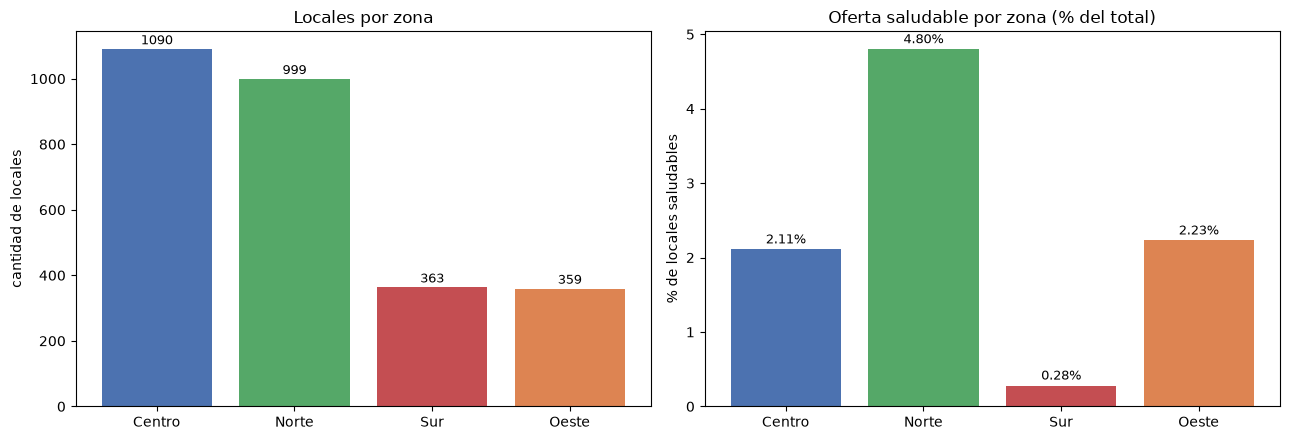

In [21]:
%matplotlib inline

fig, ejes = plt.subplots(1, 2, figsize=(13, 4.5))

orden = por_zona.sort_values('locales', ascending=False)
colores = {'Centro': '#4C72B0', 'Norte': '#55A868', 'Oeste': '#DD8452', 'Sur': '#C44E52'}

ejes[0].bar(orden.index, orden['locales'], color=[colores[z] for z in orden.index])
ejes[0].set_title('Locales por zona')
ejes[0].set_ylabel('cantidad de locales')
for i, v in enumerate(orden['locales']):
    ejes[0].text(i, v + 15, str(int(v)), ha='center', fontsize=9)

ejes[1].bar(orden.index, orden['share_salud'], color=[colores[z] for z in orden.index])
ejes[1].set_title('Oferta saludable por zona (% del total)')
ejes[1].set_ylabel('% de locales saludables')
for i, v in enumerate(orden['share_salud']):
    ejes[1].text(i, v + 0.08, f'{v:.2f}%', ha='center', fontsize=9)

plt.tight_layout()
plt.savefig('../images/01_volumen_y_saludable_por_zona.png', dpi=150, bbox_inches='tight')
plt.show()


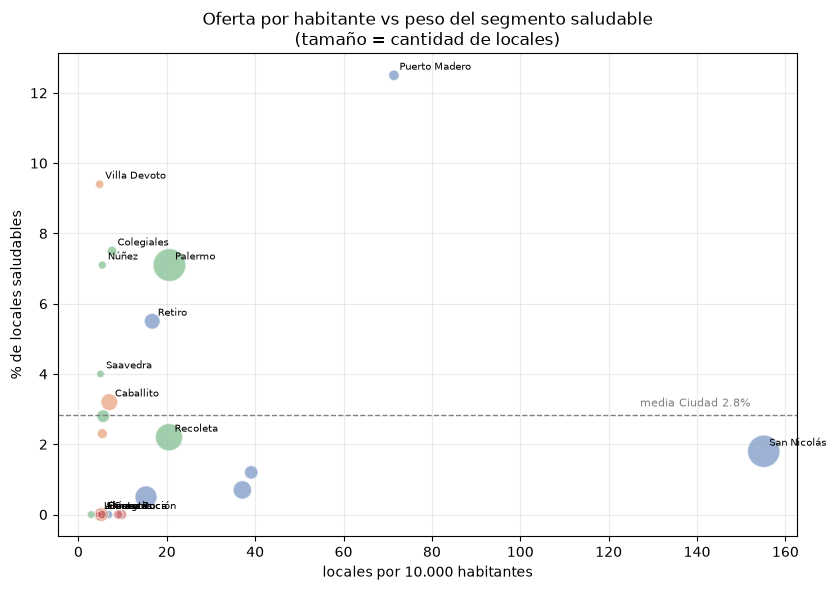

In [22]:
fig, ax = plt.subplots(figsize=(8.5, 6))

ax.scatter(
    durante['loc_10k'], durante['share_salud'],
    s=durante['locales'] * 1.2, alpha=0.55,
    c=[colores[z] for z in durante['zona']], edgecolor='white', linewidth=1,
)
ax.axhline(media_ciudad, color='grey', linestyle='--', linewidth=1)
ax.text(durante['loc_10k'].max() * 0.98, media_ciudad + 0.25,
        f'media Ciudad {media_ciudad:.1f}%', ha='right', fontsize=8, color='grey')

etiquetar = durante.nlargest(8, 'share_salud').index.tolist() + \
            durante.nsmallest(6, 'share_salud').index.tolist() + \
            durante.nlargest(3, 'locales').index.tolist()
for barrio in dict.fromkeys(etiquetar):
    fila = durante.loc[barrio]
    ax.annotate(barrio, (fila['loc_10k'], fila['share_salud']),
                fontsize=7, xytext=(4, 4), textcoords='offset points')

ax.set_xlabel('locales por 10.000 habitantes')
ax.set_ylabel('% de locales saludables')
ax.set_title('Oferta por habitante vs peso del segmento saludable\n(tamaño = cantidad de locales)')
ax.grid(alpha=0.25)
plt.tight_layout()
plt.savefig('../images/02_dispersion_densidad_saludable.png', dpi=150, bbox_inches='tight')
plt.show()


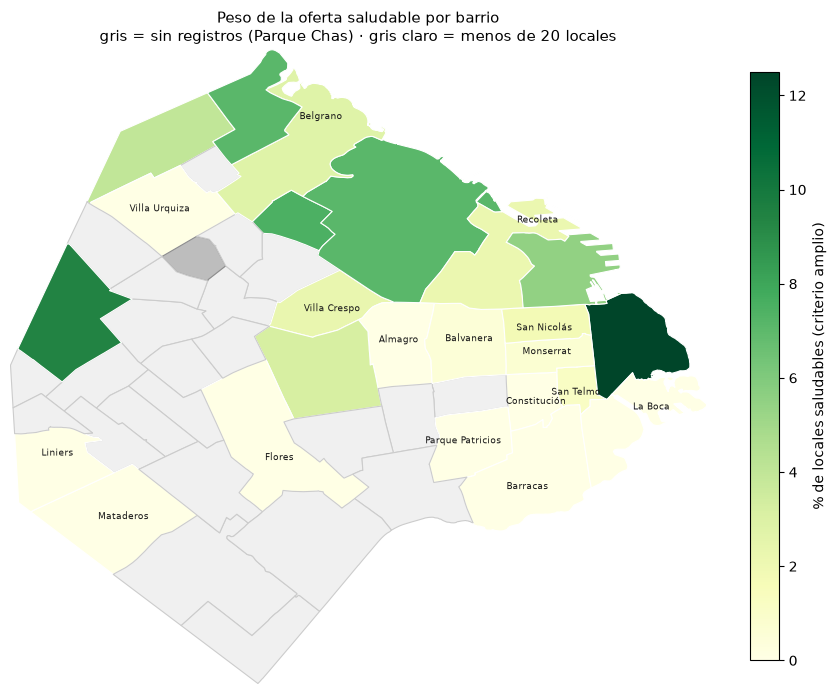

In [23]:
def anillos(geometria):
    """Devuelve el anillo exterior de cada polígono (ignora los huecos)."""
    if geometria['type'] == 'Polygon':
        return [geometria['coordinates'][0]]
    return [poligono[0] for poligono in geometria['coordinates']]


fig, ax = plt.subplots(figsize=(9, 11))
cmap = plt.get_cmap('YlGn')
norm = Normalize(vmin=0, vmax=tabla['share_salud'].max())

todos_los_anillos = []

for feature in geo['features']:
    nombre = canonico.get(clave(feature['properties']['BARRIO']), feature['properties']['BARRIO'])
    parches = [MplPolygon(anillo, closed=True) for anillo in anillos(feature['geometry'])]
    todos_los_anillos.extend(anillos(feature['geometry']))

    if nombre not in tabla.index:
        color, borde = '#bdbdbd', '#8d8d8d'      # Parque Chas: sin registros
    elif tabla.loc[nombre, 'locales'] < UMBRAL_VOLUMEN:
        color, borde = '#f0f0f0', '#cccccc'      # volumen insuficiente
    else:
        color, borde = cmap(norm(tabla.loc[nombre, 'share_salud'])), 'white'

    ax.add_collection(PatchCollection(parches, facecolor=color, edgecolor=borde, linewidth=0.8))

# Etiquetas: solo los candidatos del cuadrante A
for barrio in tabla[tabla['cuadrante'].str.startswith('A')].index:
    feature = next(f for f in geo['features']
                   if canonico.get(clave(f['properties']['BARRIO'])) == barrio)
    puntos = anillos(feature['geometry'])[0]
    cx = sum(p[0] for p in puntos) / len(puntos)
    cy = sum(p[1] for p in puntos) / len(puntos)
    ax.text(cx, cy, barrio, fontsize=6.5, ha='center', va='center', color='#1a1a1a')

xs = [p[0] for anillo in todos_los_anillos for p in anillo]
ys = [p[1] for anillo in todos_los_anillos for p in anillo]
ax.set_xlim(min(xs), max(xs))
ax.set_ylim(min(ys), max(ys))
ax.set_aspect('equal')
ax.axis('off')
ax.set_title('Peso de la oferta saludable por barrio\n'
             'gris = sin registros (Parque Chas) · gris claro = menos de 20 locales', fontsize=11)

fig.colorbar(ScalarMappable(norm=norm, cmap=cmap), ax=ax, shrink=0.55,
             label='% de locales saludables (criterio amplio)')

plt.tight_layout()
plt.savefig('../images/03_mapa_share_saludable.png', dpi=150, bbox_inches='tight')
plt.show()


## 13. Síntesis

Lo que sostienen los datos:

1. **La oferta está muy concentrada.** Los 5 barrios más grandes tienen más de un tercio de los locales de la Ciudad. El mercado no está repartido.

2. **Densidad por habitante y por superficie dan rankings distintos.** Puerto Madero sube 14 puestos al medir por superficie; Almagro baja 14. Cualquier conclusión que use solo habitantes está mezclando residentes con gente de paso.

3. **La estructura de rubros se parece en las cuatro zonas, las cocinas no.** En todas domina RESTAURANTE (67-74%) y después CAFE. Pero en `cocina` hay matices: el Norte es el que menos apuesta a lo cotidiano (20% de MINUTAS contra 32% del Centro) y es donde más se sostienen cocinas de ticket alto. La diferencia entre zonas no está en qué tipo de negocio hay, sino en qué cocinas puede bancar cada una.

4. **El Sur tiene el share saludable más bajo y el mejor nivel de completitud de datos.** 0,3% contra 4,8% del Norte. Como el Sur tiene solo 4,4% de `SIN DATO` en `cocina` (el más bajo de las cuatro zonas), el hallazgo no se explica por datos faltantes.

5. **El share saludable no se explica por el volumen ni por el azar.** La correlación entre cantidad de locales y share saludable es 0,06 (nula): los barrios grandes no son automáticamente más saludables. En cambio, la correlación con verde por habitante es 0,59 y con ticket alto, 0,65. La oferta saludable aparece en los barrios que también tienen consumo de perfil más alto y más espacio verde. **Eso es una señal de demanda, no solo de oferta.**

6. **Los proxies de poder adquisitivo coinciden entre sí (r ≈ 0,78)** y ordenan a los barrios de forma plausible (Puerto Madero, Villa Devoto, Palermo, Retiro, Núñez, Belgrano). Sirven para describir perfil de consumo, no para estimar ingreso.

7. **Hay barrios con oferta suficiente y cero locales saludables.** Son los candidatos del cuadrante A: hay mercado, falta el segmento. Nueve de ellos aguantan además el criterio más estricto ("cero saludables"), así que la lista no depende de dónde se ponga el corte.

8. **23 de 47 barrios no entran en ningún ranking.** Con menos de 20 locales no se puede concluir nada. Es la mitad de la Ciudad y hay que decirlo.

## 14. Limitaciones a declarar en el informe

1. **No hay precios ni alquileres.** El poder adquisitivo se aproxima con composición de la oferta, no se mide.
2. **La población es Censo 2010.** Es la única disponible por barrio. Para comparar barrios entre sí sirve; para valores absolutos está desactualizada.
3. **No hay demanda.** El cruce oferta/demanda es el punto 2 (Trends) y solo se puede hacer a nivel CABA/categoría, no por barrio.
4. **Snapshot, no serie temporal.** No se puede ver crecimiento ni estacionalidad.
5. **Parque Chas no tiene registros.** No se puede afirmar que "no tiene oferta".
6. **`SIN DATO` en `cocina` (356 registros)** subestima el segmento saludable. Ya se chequeó que no explica la diferencia por zona.
7. **El HHI mide diversidad de rubros, no competencia real.** Sin ventas no se puede medir competencia.
8. **Los proxies de precio son eso: proxies.** Puerto Madero y Retiro están inflados por turismo y oficinas.

## 15. Qué le sirve al resto del equipo

- **Punto 2 (Trends):** el cruce demanda/oferta solo tiene sentido a nivel CABA y por categoría de cocina, no por barrio. El share saludable de la Ciudad es 2,8%: esa es la vara contra la que comparar el interés de búsqueda.
- **Punto 3 (reseñas):** los barrios del cuadrante A son los que más sentido tiene muestrear. No hace falta scrapear toda la Ciudad.
- **Punto 4 (competencia):** el mapa de puntos y la tabla maestra están listos para cruzar. Ojo: no volver a limpiar el CSV ni tratar `SIN DATO` como "no saludable".
